# Dental Health Dataset — Complete EDA with Seaborn, Code Explanation, Graph Reading, and Result Insights

This notebook is designed for students who are learning **Exploratory Data Analysis (EDA)** in Python.

For every major visualization, the notebook uses four learning headings:

1. **Purpose** — why we are making the graph.
2. **Code Explanation** — what each important code parameter means.
3. **How to Read the Graph** — how students should interpret the visual elements.
4. **Result / Insight** — what the graph tells us about the dental dataset.


## Cell 1 — Import required libraries

This cell imports the Python libraries needed for EDA.

- `pandas` is used to load, clean, filter, and analyze tabular data.
- `numpy` is used for numerical operations.
- `matplotlib.pyplot` is used as the base plotting library.
- `seaborn` is used for attractive statistical visualizations.
- `warnings.filterwarnings("ignore")` hides unnecessary warning messages during class practice.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

a = pd.set_option("display.max_columns", 50)
b = pd.set_option("display.width", 120)

sns.set_theme(style="whitegrid")



## Cell 2 — Load the dental dataset

This cell reads the CSV file using `pd.read_csv()` and stores it in a DataFrame named `df`.

A DataFrame is like an Excel table inside Python.  
The `head()` function displays the first 5 rows so that we can quickly understand the structure of the dataset.


In [ ]:
df = pd.read_csv("dental_health_eda_dataset.csv")
df.head()


,PatientID,Age,Gender,BrushingFrequency,SugarIntakePerDay,Smoking,PlaqueIndex,GumBleeding,Cavities,MissingTeeth,DMFT_Index,LastDentalVisit,OrthodonticTreatment,TreatmentCostPKR,TreatmentNeed
0,1,57,Female,Once daily,6.5,No,1.72,No,3,0,5,> 2 years,No,9784,High
1,2,20,Female,Once daily,NaN,Yes,2.35,Yes,2,0,2,1-2 years,No,9102,High
2,3,66,Male,Once daily,5.2,Yes,NaN,Yes,5,2,8,> 2 years,No,24404,High
3,4,26,Male,Twice daily,7.4,No,3.09,Yes,0,0,1,Never,No,4378,High
4,5,29,Female,Once daily,5.6,No,3.78,Yes,2,0,4,< 6 months,No,11834,High


## Cell 3 — Check shape, column names, and data types

This cell gives a basic overview of the dataset.

- `df.shape` shows the number of rows and columns.
- `df.columns.tolist()` shows all column names.
- `df.info()` shows data types and non-null values.

This is important because before analysis we must know what type of data we have.


In [ ]:
print("Shape of dataset:", df.shape)
print("\nColumn names:")
display(df.columns.tolist())

print("\nDataset information:")
df.info()


Shape of dataset: (505, 15)

Column names:


['PatientID',
 'Age',
 'Gender',
 'BrushingFrequency',
 'SugarIntakePerDay',
 'Smoking',
 'PlaqueIndex',
 'GumBleeding',
 'Cavities',
 'MissingTeeth',
 'DMFT_Index',
 'LastDentalVisit',
 'OrthodonticTreatment',
 'TreatmentCostPKR',
 'TreatmentNeed']


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 505 entries, 0 to 504
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   PatientID             505 non-null    int64  
 1   Age                   505 non-null    int64  
 2   Gender                505 non-null    object 
 3   BrushingFrequency     494 non-null    object 
 4   SugarIntakePerDay     485 non-null    float64
 5   Smoking               505 non-null    object 
 6   PlaqueIndex           490 non-null    float64
 7   GumBleeding           505 non-null    object 
 8   Cavities              505 non-null    int64  
 9   MissingTeeth          505 non-null    int64  
 10  DMFT_Index            505 non-null    int64  
 11  LastDentalVisit       495 non-null    object 
 12  OrthodonticTreatment  505 non-null    object 
 13  TreatmentCostPKR      505 non-null    int64  
 14  TreatmentNeed         505 non-null    object 
dtypes

## Cell 4 — Understand each column

This cell creates a small data dictionary explaining what each column means.  
A data dictionary is very useful when students or analysts are new to a dataset.


In [ ]:
data_dictionary = pd.DataFrame({
    "Column": [
        "PatientID", "Age", "Gender", "BrushingFrequency", "SugarIntakePerDay",
        "Smoking", "PlaqueIndex", "GumBleeding", "Cavities", "MissingTeeth",
        "DMFT_Index", "LastDentalVisit", "OrthodonticTreatment",
        "TreatmentCostPKR", "TreatmentNeed"
    ],
    "Meaning": [
        "Unique ID of each patient",
        "Age of the patient in years",
        "Gender of the patient",
        "How often the patient brushes teeth",
        "Estimated number of sugary items consumed per day",
        "Whether the patient smokes or not",
        "Plaque score from 0 to 5; higher means worse oral hygiene",
        "Whether gums bleed during brushing or examination",
        "Number of detected cavities",
        "Number of missing teeth",
        "Decayed, Missing, and Filled Teeth index",
        "Time since last dental visit",
        "Whether patient is under orthodontic treatment",
        "Estimated dental treatment cost in Pakistani Rupees",
        "Low, Medium, or High dental treatment need"
    ]
})

data_dictionary


,Column,Meaning
0,PatientID,Unique ID of each patient
1,Age,Age of the patient in years
2,Gender,Gender of the patient
3,BrushingFrequency,How often the patient brushes teeth
4,SugarIntakePerDay,Estimated number of sugary items consumed per day
5,Smoking,Whether the patient smokes or not
6,PlaqueIndex,Plaque score from 0 to 5; higher means worse o...
7,GumBleeding,Whether gums bleed during brushing or examination
8,Cavities,Number of detected cavities
9,MissingTeeth,Number of missing teeth


## Cell 5 — Check missing values

Missing values are empty values in the dataset.

This cell calculates:
- `missing_count`: number of missing values in each column
- `missing_percent`: percentage of missing values in each column

This helps us decide which columns need cleaning.


In [ ]:
missing_count = df.isnull().sum().sort_values(ascending=False)
missing_percent = (df.isnull().mean() * 100).sort_values(ascending=False)
missing_count
#20/505 * 100
#15/505 * 100

,0
SugarIntakePerDay,20
PlaqueIndex,15
BrushingFrequency,11
LastDentalVisit,10
Gender,0
PatientID,0
Age,0
Smoking,0
GumBleeding,0
MissingTeeth,0


In [ ]:
missing_percent

,0
SugarIntakePerDay,3.960396
PlaqueIndex,2.970297
BrushingFrequency,2.178218
LastDentalVisit,1.980198
Gender,0.000000
PatientID,0.000000
Age,0.000000
Smoking,0.000000
GumBleeding,0.000000
MissingTeeth,0.000000


In [ ]:


missing_table = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage": missing_percent.round(2)
})

missing_table[missing_table["Missing Count"] > 0]


,Missing Count,Missing Percentage
SugarIntakePerDay,20,3.96
PlaqueIndex,15,2.97
BrushingFrequency,11,2.18
LastDentalVisit,10,1.98


## Cell 6 — Visualize Missing Values Using Seaborn Heatmap

### Purpose
The purpose of this graph is to quickly identify where missing values are present in the dental dataset.

### Code Explanation
`sns.heatmap(df.isnull(), cbar=False)` converts the missing-value table into a visual heatmap.  
`df.isnull()` returns `True` where a value is missing and `False` where a value is present.  
`cbar=False` means the color bar is hidden because this graph only needs to show missing vs non-missing values.

### How to Read the Graph
Each row represents a patient record and each column represents a dataset feature. A different colored mark means a missing value. If a column has many missing marks, that column needs cleaning or imputation.

### Result / Insight
This graph helps us detect missing-value patterns before filling them. In this notebook, missing numerical values are later filled with the median and missing categorical values are filled with the mode.


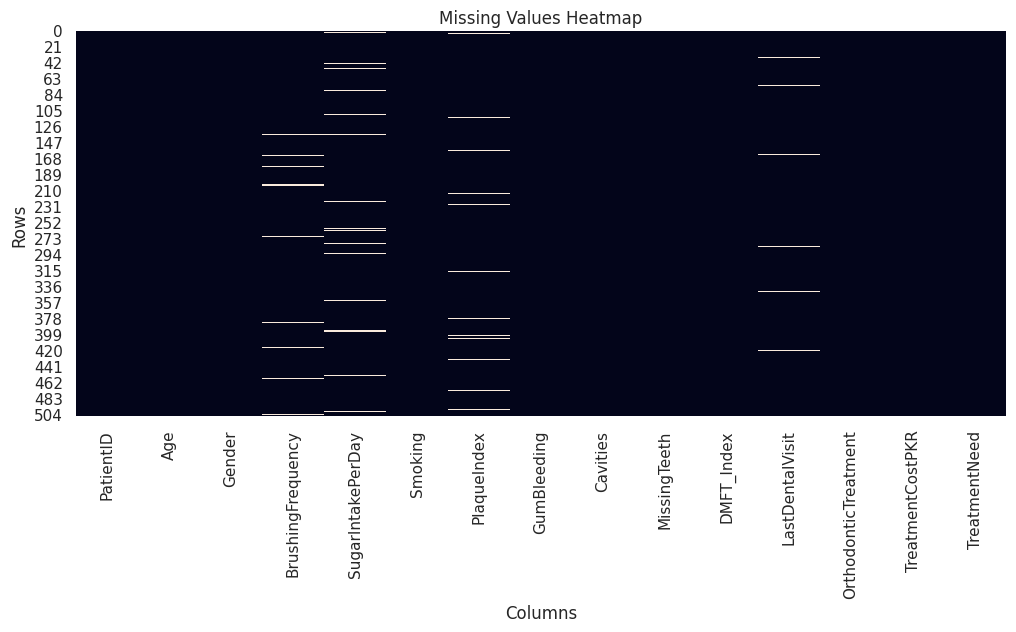

In [ ]:
plt.figure(figsize=(12, 5))
sns.heatmap(df.isnull(), cbar=False)
plt.title("Missing Values Heatmap")
plt.xlabel("Columns")
plt.ylabel("Rows")
plt.show()


## Cell 7 — Check duplicate rows

Duplicate rows can occur when data is copied, merged, or entered twice.

- `df.duplicated().sum()` counts exact duplicate rows.
- If duplicates exist, we can remove them using `drop_duplicates()`.


In [ ]:
df.duplicated().sum()

np.int64(5)

In [ ]:
duplicate_count = df.duplicated().sum()
print("Number of duplicate rows:", duplicate_count)


Number of duplicate rows: 5


## Cell 8 — Clean text columns

Sometimes text columns contain extra spaces, for example `" Male "` instead of `"Male"`.

This cell:
- selects all text/object columns
- removes extra spaces using `.str.strip()`

This avoids mistakes during grouping and visualization.


In [ ]:
text_columns = df.select_dtypes(include="object").columns

df[text_columns] = df[text_columns].apply(lambda col: col.astype("string").str.strip())

df[text_columns].head()
#object-text,special character number
#String-Text "uzair"

,Gender,BrushingFrequency,Smoking,GumBleeding,LastDentalVisit,OrthodonticTreatment,TreatmentNeed
0,Female,Once daily,No,No,> 2 years,No,High
1,Female,Once daily,Yes,Yes,1-2 years,No,High
2,Male,Once daily,Yes,Yes,> 2 years,No,High
3,Male,Twice daily,No,Yes,Never,No,High
4,Female,Once daily,No,Yes,< 6 months,No,High


## Cell 9 — Remove duplicate rows

This cell removes duplicate rows and creates a clean copy of the dataset.

We use `.copy()` to avoid chained assignment problems later.


In [ ]:
df = df.drop_duplicates().copy()

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (500, 15)


## Cell 10 — Fill missing values

For EDA practice, we use simple missing-value treatment:

- Numerical columns are filled using the **median**.
- Categorical columns are filled using the **mode**.

Median is useful because it is less affected by extreme values.  
Mode is useful for categorical columns because it selects the most common category.


In [ ]:
#median: Center value after align in a ascending order

In [ ]:
#Q1
df[col].mode()[0]

NameError: name 'col' is not defined

In [ ]:
#Q2
numeric_cols = df.select_dtypes(include=["int64", "float64"]).columns
categorical_cols = df.select_dtypes(include=["object", "string"]).columns

df[numeric_cols] = df[numeric_cols].fillna(df[numeric_cols].median(numeric_only=True))

for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

print("Remaining missing values:", df.isnull().sum().sum())


Remaining missing values: 0


## Cell 11 — Summary statistics

The `describe()` function gives important statistics.

For numerical columns, it shows:
- count
- mean
- standard deviation
- minimum
- quartiles
- maximum

These values help us understand the spread of the data.


In [ ]:
df.describe().T


,count,mean,std,min,25%,50%,75%,max
PatientID,500.0,250.50000,144.481833,1.0,125.7500,250.50,375.25,500.00
Age,500.0,39.79600,20.355320,6.0,22.0000,39.50,58.00,74.00
SugarIntakePerDay,500.0,4.45620,1.923013,0.0,3.1000,4.50,5.70,9.80
PlaqueIndex,500.0,2.29976,0.762941,0.4,1.7375,2.27,2.83,4.72
Cavities,500.0,1.64400,1.430159,0.0,1.0000,1.00,2.00,8.00
MissingTeeth,500.0,0.52600,0.850159,0.0,0.0000,0.00,1.00,4.00
DMFT_Index,500.0,2.91200,1.826178,0.0,2.0000,3.00,4.00,10.00
TreatmentCostPKR,500.0,9970.05400,5167.341692,564.0,6166.7500,9250.00,12814.00,31380.00


## Cell 12 — Categorical column summary

This cell checks the frequency of important categorical columns.

`value_counts()` tells us how many patients belong to each category.


In [ ]:
categorical_summary_columns = [
    "Gender", "BrushingFrequency", "Smoking", "GumBleeding",
    "LastDentalVisit", "OrthodonticTreatment", "TreatmentNeed"
]

for col in categorical_summary_columns:
    print(f"\n{col}")
    print(df[col].value_counts())



Gender
Gender
Female    251
Male      249
Name: count, dtype: Int64

BrushingFrequency
BrushingFrequency
Once daily     220
Twice daily    173
Irregular      107
Name: count, dtype: Int64

Smoking
Smoking
No     410
Yes     90
Name: count, dtype: Int64

GumBleeding
GumBleeding
Yes    279
No     221
Name: count, dtype: Int64

LastDentalVisit
LastDentalVisit
6-12 months    148
< 6 months     109
1-2 years      103
> 2 years      100
Never           40
Name: count, dtype: Int64

OrthodonticTreatment
OrthodonticTreatment
No     425
Yes     75
Name: count, dtype: Int64

TreatmentNeed
TreatmentNeed
High      238
Medium    221
Low        41
Name: count, dtype: Int64


## Cell 13 — Create age groups

Raw age values are sometimes difficult to interpret.

This cell creates a new column called `AgeGroup` using `pd.cut()`.

Age groups make it easier to compare children, young adults, adults, and senior patients.


In [ ]:
age_bins = [0, 12, 19, 35, 50, 100]
age_labels = ["Child", "Teen", "Young Adult", "Adult", "Senior"]

df["AgeGroup"] = pd.cut(df["Age"], bins=age_bins, labels=age_labels)

df[["Age", "AgeGroup"]].head()


,Age,AgeGroup
0,57,Senior
1,20,Young Adult
2,66,Senior
3,26,Young Adult
4,29,Young Adult


## Cell 14 — Distribution of Age Using Seaborn Histogram

### Purpose
The purpose of this graph is to understand the age distribution of dental patients.

### Code Explanation
`sns.histplot(data=df, x="Age", bins=20, kde=True)` creates a histogram of the `Age` column.  
`bins=20` divides the age range into 20 intervals.  
`kde=True` adds a smooth density curve that shows the overall shape of the distribution.

### How to Read the Graph
The x-axis shows age and the y-axis shows the number of patients. Taller bars mean more patients belong to that age range. The KDE curve helps us see whether the distribution is balanced, skewed, or concentrated in certain age groups.

### Result / Insight
The dataset includes patients from children to seniors. The median age is around 39.5 years, so the dataset contains many adult patients and can be used to compare dental health across different age groups.


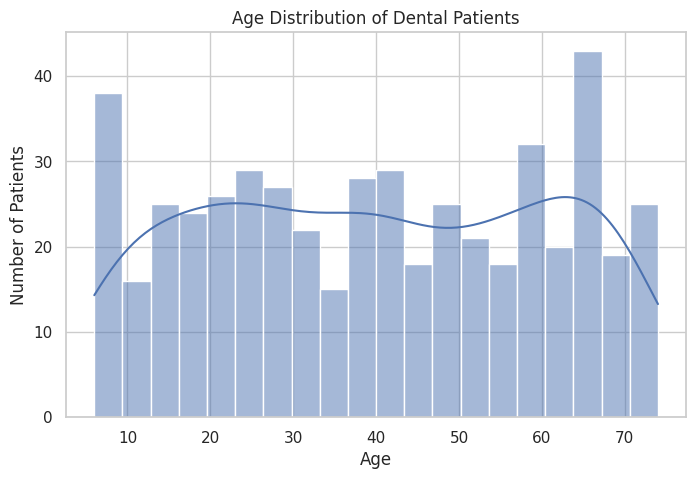

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Age", bins=20, kde=True)
plt.title("Age Distribution of Dental Patients")
plt.xlabel("Age")
plt.ylabel("Number of Patients")
plt.show()


## Cell 15 — Count Plot of Treatment Need

### Purpose
The purpose of this graph is to count how many patients have Low, Medium, or High treatment need.

### Code Explanation
`sns.countplot(data=df, x="TreatmentNeed")` counts the number of records in each treatment-need category. The `order` parameter arranges the categories as Low, Medium, and High.

### How to Read the Graph
The x-axis shows treatment need categories. The y-axis shows patient count. The tallest bar represents the category with the highest number of patients.

### Result / Insight
In this dataset, High treatment need has the largest count, followed by Medium, while Low has the smallest count. This means many patients in the sample require serious dental attention.


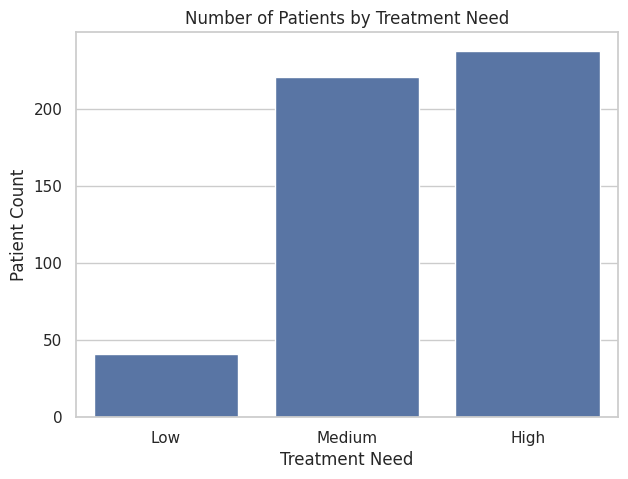

In [ ]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="TreatmentNeed", order=["Low", "Medium", "High"])
plt.title("Number of Patients by Treatment Need")
plt.xlabel("Treatment Need")
plt.ylabel("Patient Count")
plt.show()


## Cell 16 — Brushing Frequency vs Treatment Need

### Purpose
The purpose of this graph is to compare brushing habits with dental treatment need.

### Code Explanation
`sns.countplot(data=df, x="BrushingFrequency", hue="TreatmentNeed")` counts brushing-frequency categories and splits each bar by treatment need using `hue`.

### How to Read the Graph
For each brushing-frequency group, compare the colored bars. If the High-treatment bar is taller in a brushing group, that group has more patients with serious dental issues.

### Result / Insight
This visualization helps students check whether irregular brushing is linked with higher treatment need. It is useful for explaining how oral hygiene behavior can influence dental health.


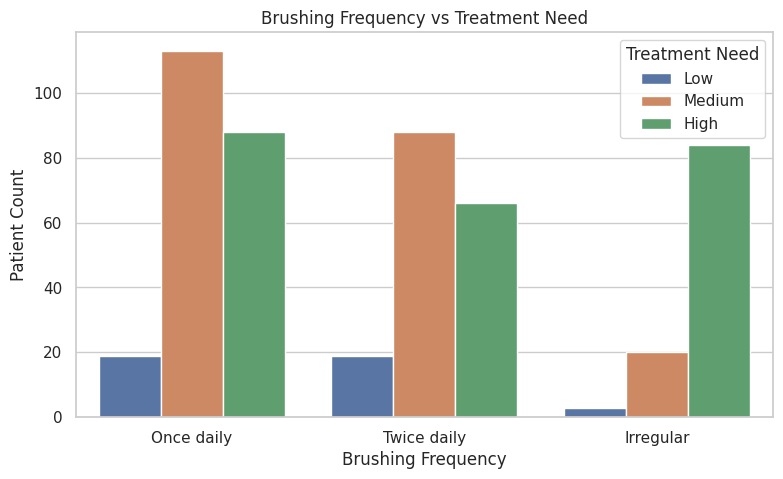

In [ ]:
plt.figure(figsize=(9, 5))
sns.countplot(data=df, x="BrushingFrequency", hue="TreatmentNeed", hue_order=["Low", "Medium", "High"])
plt.title("Brushing Frequency vs Treatment Need")
plt.xlabel("Brushing Frequency")
plt.ylabel("Patient Count")
plt.legend(title="Treatment Need")
plt.show()


## Cell 17 — Boxplot: Sugar Intake and Cavities

### Purpose
The purpose of this graph is to compare sugar intake across different numbers of cavities.

### Code Explanation
`sns.boxplot(data=df, x="Cavities", y="SugarIntakePerDay")` creates a boxplot where each cavity count has its own sugar-intake distribution.

### How to Read the Graph
The middle line inside each box is the median. The lower edge is Q1 and the upper edge is Q3. The distance between Q1 and Q3 is called IQR. Dots outside the whiskers are possible outliers.

### Result / Insight
The graph helps us see whether patients with more cavities generally consume more sugar. In the dataset, median sugar intake tends to be higher for patients with more cavities, which supports the idea that sugar intake is related to dental decay risk.


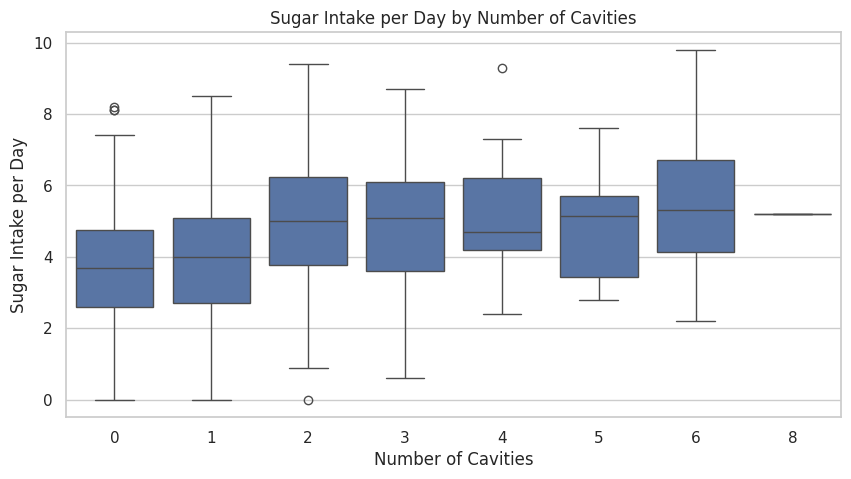

In [ ]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x="Cavities", y="SugarIntakePerDay")
plt.title("Sugar Intake per Day by Number of Cavities")
plt.xlabel("Number of Cavities")
plt.ylabel("Sugar Intake per Day")
plt.show()


## Cell 18 — Boxplot: Plaque Index by Brushing Frequency

### Purpose
The purpose of this graph is to compare plaque index across brushing-frequency groups.

### Code Explanation
`sns.boxplot(data=df, x="BrushingFrequency", y="PlaqueIndex")` compares numerical plaque-index values for each brushing habit category.

### How to Read the Graph
A higher median line means that group usually has higher plaque. A taller box means more variation. Dots outside the whiskers show unusual plaque-index values.

### Result / Insight
Irregular brushers show a higher median plaque index than once-daily and twice-daily brushers. This suggests that poor brushing habits are linked with higher plaque buildup.


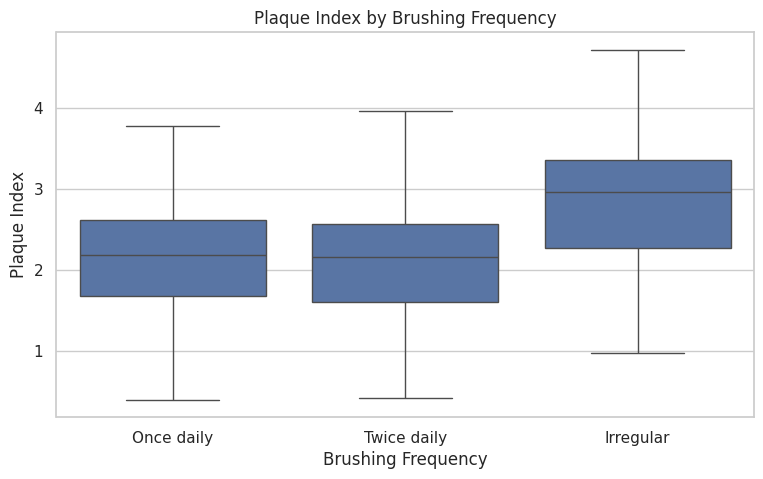

In [ ]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="BrushingFrequency", y="PlaqueIndex")
plt.title("Plaque Index by Brushing Frequency")
plt.xlabel("Brushing Frequency")
plt.ylabel("Plaque Index")
plt.show()


## Cell 19 — Scatter Plot: Plaque Index vs Treatment Cost

### Purpose
The purpose of this graph is to examine the relationship between plaque index and treatment cost.

### Code Explanation
`sns.scatterplot(data=df, x="PlaqueIndex", y="TreatmentCostPKR", hue="TreatmentNeed")` plots each patient as one point. The `hue` parameter colors points according to treatment need.

### How to Read the Graph
Each dot represents one patient. If points move upward as plaque index increases, it suggests a positive relationship. Colors help identify whether high-treatment-need patients are located in higher-cost areas.

### Result / Insight
This graph helps show that patients with higher plaque index often have higher treatment cost and more serious treatment need. It supports the idea that plaque can be an important dental-health indicator.


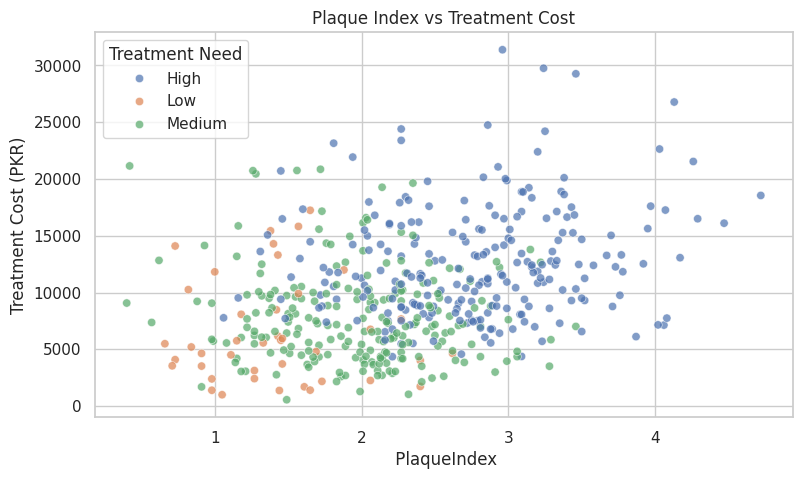

In [ ]:
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df, x="PlaqueIndex", y="TreatmentCostPKR", hue="TreatmentNeed", alpha=0.7)
plt.title("Plaque Index vs Treatment Cost")
plt.xlabel(" PlaqueIndex")
plt.ylabel("Treatment Cost (PKR)")
plt.legend(title="Treatment Need")
plt.show()


## Cell 20 — Count Plot: Smoking and Gum Bleeding

### Purpose
The purpose of this graph is to compare gum bleeding between smokers and non-smokers.

### Code Explanation
`sns.countplot(data=df, x="Smoking", hue="GumBleeding")` counts smoker and non-smoker groups and separates them by gum bleeding status using `hue`.

### How to Read the Graph
Compare the Yes and No gum-bleeding bars inside each smoking category. A taller Yes bar means more patients in that group reported gum bleeding.

### Result / Insight
This graph helps students visually compare oral health symptoms between smoking groups. In this dataset, gum bleeding is common in both smokers and non-smokers, so further statistical testing would be needed before making a strong conclusion.


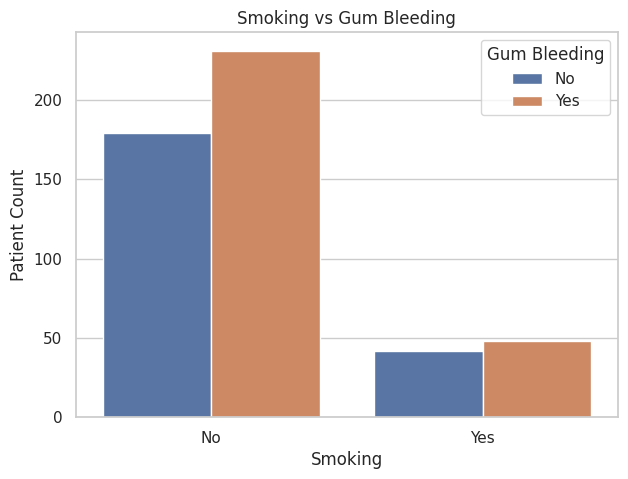

In [ ]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Smoking", hue="GumBleeding")
plt.title("Smoking vs Gum Bleeding")
plt.xlabel("Smoking")
plt.ylabel("Patient Count")
plt.legend(title="Gum Bleeding")
plt.show()


## Cell 21 — Bar Plot: Average Treatment Cost by Treatment Need

### Purpose
The purpose of this graph is to compare average treatment cost for Low, Medium, and High treatment need.

### Code Explanation
`sns.barplot(data=df, x="TreatmentNeed", y="TreatmentCostPKR", estimator=np.mean, errorbar=None)` calculates and displays the mean treatment cost for each category. `errorbar=None` hides confidence intervals to keep the graph simple for students.

### How to Read the Graph
The x-axis shows treatment-need categories. The y-axis shows average treatment cost in PKR. A taller bar means a higher average cost.

### Result / Insight
High treatment need has the highest average cost, Medium has a lower average cost, and Low has the lowest average cost. This confirms that more serious dental cases usually require more expensive treatment.


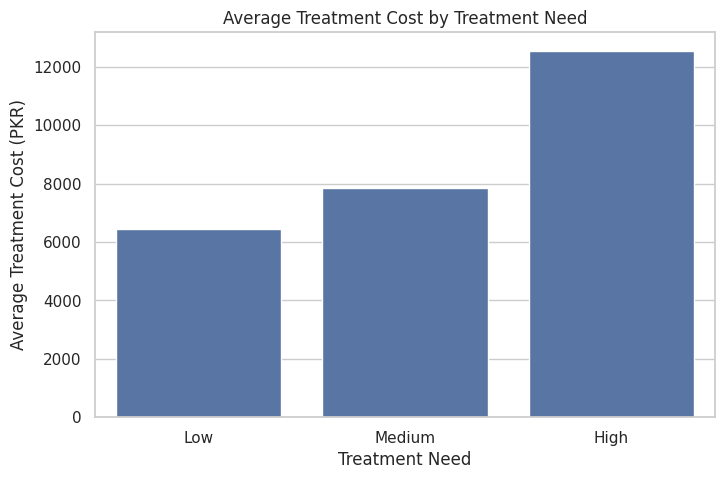

In [ ]:
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x="TreatmentNeed", y="TreatmentCostPKR", order=["Low", "Medium", "High"], estimator=np.mean, errorbar=None)
plt.title("Average Treatment Cost by Treatment Need")
plt.xlabel("Treatment Need")
plt.ylabel("Average Treatment Cost (PKR)")
plt.show()


## Cell 22 — Correlation analysis

Correlation measures the relationship between numerical columns.

- Positive correlation means both variables tend to increase together.
- Negative correlation means one variable increases while the other decreases.
- Correlation close to 0 means weak linear relationship.


In [ ]:
correlation_matrix = df.corr(numeric_only=True)

correlation_matrix.round(2)


,PatientID,Age,SugarIntakePerDay,PlaqueIndex,Cavities,MissingTeeth,DMFT_Index,TreatmentCostPKR
PatientID,1.00,0.01,0.01,0.00,0.01,0.01,-0.01,0.00
Age,0.01,1.00,-0.02,-0.05,-0.00,0.51,0.22,0.32
SugarIntakePerDay,0.01,-0.02,1.00,0.18,0.25,-0.06,0.18,0.16
PlaqueIndex,0.00,-0.05,0.18,1.00,0.31,-0.06,0.22,0.32
Cavities,0.01,-0.00,0.25,0.31,1.00,-0.05,0.76,0.70
MissingTeeth,0.01,0.51,-0.06,-0.06,-0.05,1.00,0.42,0.61
DMFT_Index,-0.01,0.22,0.18,0.22,0.76,0.42,1.00,0.84
TreatmentCostPKR,0.00,0.32,0.16,0.32,0.70,0.61,0.84,1.00


## Cell 23 — Correlation Heatmap Using Seaborn

### Purpose
The purpose of this graph is to show relationships between numerical columns in the dental dataset.

### Code Explanation
`sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm")` visualizes correlation values. `annot=True` writes numbers inside the boxes. `fmt=".2f"` rounds values to 2 decimal places. `cmap="coolwarm"` uses a color scale to show negative and positive relationships.

### How to Read the Graph
Correlation values range from -1 to +1. Values close to +1 show strong positive relationship. Values close to -1 show strong negative relationship. Values close to 0 show weak or no linear relationship.

### Result / Insight
Treatment cost has a strong positive relationship with DMFT index, cavities, and missing teeth. This means patients with worse dental-health indicators usually have higher treatment cost.


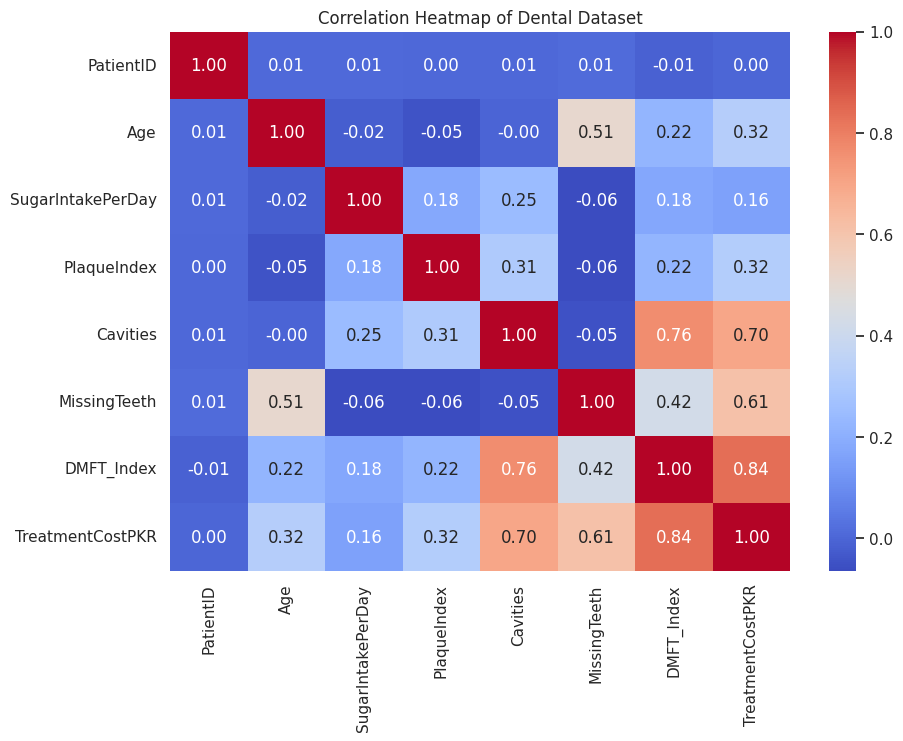

In [ ]:
plt.figure(figsize=(10, 7))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap of Dental Dataset")
plt.show()


## Cell 24 — Groupby analysis

`groupby()` is used to summarize data by categories.

Here we calculate average values by `TreatmentNeed`.

This helps us compare dental indicators for Low, Medium, and High treatment-need groups.


In [ ]:
treatment_summary = (
    df.groupby("TreatmentNeed")
      .agg(
          Patients=("PatientID", "count"),
          Avg_Age=("Age", "mean"),
          Avg_Sugar=("SugarIntakePerDay", "mean"),
          Avg_Plaque=("PlaqueIndex", "mean"),
          Avg_Cavities=("Cavities", "mean"),
          Avg_Cost=("TreatmentCostPKR", "mean")
      )
      .reindex(["Low", "Medium", "High"])
      .round(2)
)

treatment_summary


,Patients,Avg_Age,Avg_Sugar,Avg_Plaque,Avg_Cavities,Avg_Cost
TreatmentNeed,,,,,,
Low,41,47.37,2.48,1.41,0.29,6432.61
Medium,221,37.94,4.00,1.97,0.95,7837.38
High,238,40.22,5.22,2.76,2.53,12559.79


## Cell 25 — Pivot table

A pivot table summarizes values in a two-dimensional table.

Here we calculate average treatment cost based on:
- rows: brushing frequency
- columns: smoking status


In [ ]:
pivot_cost = pd.pivot_table(
    df,
    values="TreatmentCostPKR",
    index="BrushingFrequency",
    columns="Smoking",
    aggfunc="mean"
).round(2)

pivot_cost


Smoking,No,Yes
BrushingFrequency,,
Irregular,12622.25,15428.92
Once daily,8753.18,10387.45
Twice daily,9265.95,9514.85


## Cell 26 — Heatmap of Pivot Table

### Purpose
The purpose of this graph is to visualize the average treatment cost based on brushing frequency and smoking status.

### Code Explanation
`sns.heatmap(pivot_cost, annot=True, fmt=".0f", cmap="YlGnBu")` displays the pivot table as a heatmap. `annot=True` writes the average cost values inside the boxes. `fmt=".0f"` displays values without decimal places.

### How to Read the Graph
Rows represent brushing frequency and columns represent smoking status. Darker or stronger colored boxes usually indicate higher average treatment cost.

### Result / Insight
This graph helps compare combined effects of brushing habits and smoking on treatment cost. It is useful because pivot-table heatmaps summarize two categorical variables and one numerical variable in a single visual.


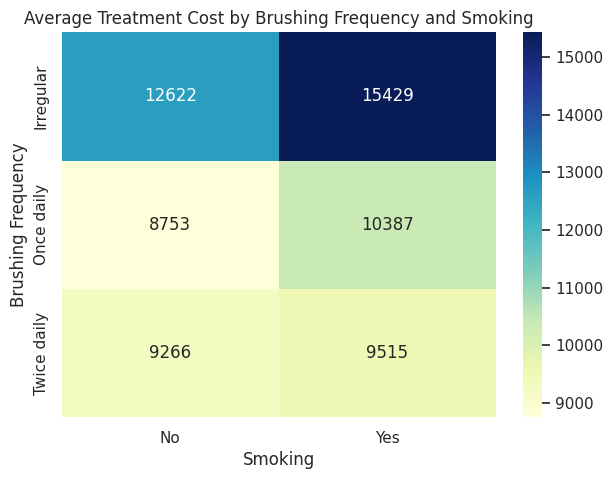

In [ ]:
plt.figure(figsize=(7, 5))
sns.heatmap(pivot_cost, annot=True, fmt=".0f", cmap="YlGnBu")
plt.title("Average Treatment Cost by Brushing Frequency and Smoking")
plt.xlabel("Smoking")
plt.ylabel("Brushing Frequency")
plt.show()


## Cell 27 — Outlier Detection Using IQR

### Purpose
The purpose of this cell is to identify unusually high or low treatment costs using the IQR method.

### Code Explanation
The code calculates Q1, Q3, and IQR for `TreatmentCostPKR`.  
`Q1` is the 25th percentile.  
`Q3` is the 75th percentile.  
`IQR = Q3 - Q1`.  
The lower and upper limits are calculated using `1.5 * IQR`.

### How to Read the Result
Any treatment cost below the lower limit or above the upper limit is considered a possible outlier. Outliers are not always wrong; they may represent special or serious dental cases.

### Result / Insight
For this dataset, the IQR method identifies a small number of unusually high treatment-cost records. These cases should be reviewed because they may represent complex dental treatments or data-entry issues.


In [ ]:
Q1 = df["TreatmentCostPKR"].quantile(0.25)
Q3 = df["TreatmentCostPKR"].quantile(0.75)
IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[(df["TreatmentCostPKR"] < lower_limit) | (df["TreatmentCostPKR"] > upper_limit)]

print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)
print("Number of treatment cost outliers:", outliers.shape[0])

outliers.head()


Lower limit: -3804.125
Upper limit: 22784.875
Number of treatment cost outliers: 9


,PatientID,Age,Gender,BrushingFrequency,SugarIntakePerDay,Smoking,PlaqueIndex,GumBleeding,Cavities,MissingTeeth,DMFT_Index,LastDentalVisit,OrthodonticTreatment,TreatmentCostPKR,TreatmentNeed,AgeGroup
2,3,66,Male,Once daily,5.2,Yes,2.27,Yes,5,2,8,> 2 years,No,24404,High,Senior
120,121,47,Male,Irregular,3.3,No,3.24,Yes,4,3,7,> 2 years,No,29753,High,Adult
129,130,67,Male,Twice daily,4.5,No,3.46,Yes,3,4,8,< 6 months,No,29263,High,Senior
160,161,58,Female,Irregular,2.8,No,2.86,No,5,2,9,< 6 months,No,24751,High,Senior
314,315,63,Female,Irregular,6.2,Yes,2.27,Yes,4,2,6,< 6 months,No,23402,High,Senior


## Cell 28 — Final cleaned dataset preview

This cell displays the final cleaned dataset after:
- removing duplicates
- cleaning text
- filling missing values
- creating age groups

This final dataset can now be used for machine learning or further analysis.


In [ ]:
df.head(10)


## Cell 29 — Save cleaned dataset

This cell saves the cleaned version of the dataset as a new CSV file.

This is useful because after EDA and cleaning, we usually save the cleaned dataset for future use.


In [ ]:
df.to_csv("dental_health_cleaned_dataset.csv", index=False)

print("Cleaned dataset saved successfully as dental_health_cleaned_dataset.csv")


# Student Practice Tasks

Try these tasks after completing the notebook:

1. Find the average number of cavities by age group.
2. Create a count plot of `LastDentalVisit`.
3. Create a boxplot of `TreatmentCostPKR` by `Smoking`.
4. Find the top 10 patients with the highest treatment cost.
5. Create a scatter plot of `SugarIntakePerDay` vs `Cavities`.
6. Find the average `PlaqueIndex` by `GumBleeding`.
7. Create a heatmap using a pivot table of `AgeGroup` and `TreatmentNeed`.
